# ETH Monte Carlo price simulation

This notebook models a range of possible future ETH prices with Monte Carlo simulation. It:

1. **Data:** downloads daily ETH-USD history from 2016 to today and caches it, then fetches the live price and circulating supply.
2. **Exploratory analysis:** looks at realized volatility, fat tails and drawdowns.
3. **Models:** simulates thousands of price paths with four models that share one function signature: GBM, Student-t, block bootstrap and a GMM regime-switching model.
4. **Outputs:** summarizes the paths as fan charts, end-price percentiles, implied market caps, the probability of ending above or touching key prices, and expected drawdowns.
5. **Strategy tester:** compares three simple trading rules across all simulated paths.
6. **Calibration check:** backtests whether the models' prediction intervals actually contained what happened.

> **This is not investment advice.** These are statistical scenarios built from past price behaviour, not forecasts. All parameters are in the config cell below. Rerun top to bottom after changing them.

In [1]:
# ================================ CONFIG ================================
# Simulation
HORIZON_DAYS      = 365        # horizon in calendar days (ETH trades 24/7, so 1 year = 365 steps)
N_PATHS           = 10_000     # Monte Carlo paths per model
DRIFT             = 0.0        # annual arithmetic drift mu of the price. 0 => E[S_T] = S_0 (martingale)
VOL_OVERRIDE      = None       # annual volatility, e.g. 0.70. None => estimate from history
VOL_LOOKBACK_DAYS = 730        # trailing window used to estimate volatility when VOL_OVERRIDE is None
SEED              = 42         # master random seed (every model draws from its own stream derived from it)

# Price levels to report probabilities for (USD). 4,946 = ETH all-time high.
ATH_PRICE  = 4_946                # intraday all-time high (Aug 2025)
THRESHOLDS = [1_000, 1_500, 2_000, 3_000, ATH_PRICE, 8_000, 10_000]
PERCENTILES = [5, 25, 50, 75, 95]

# Model settings
BLOCK_LENGTH   = 10            # block-bootstrap block length (days)
GMM_COMPONENTS = [2, 3]        # candidate numbers of regimes, chosen by BIC
GMM_WINDOW     = 30            # rolling window (days) for the regime features

# Strategy tester
LADDER = [(1.5, 0.25), (2.0, 0.25), (3.0, 0.25)]  # (multiple of entry, fraction of initial ETH sold)
DCA_INITIAL_FRACTION = 0.50    # share of capital invested on day 0; the rest is held as cash
DCA_N_TRANCHES       = 5       # that cash is split into this many equal tranches
DCA_TRIGGER_DROP     = 0.20    # buy a tranche when price is 20% below its running peak (peak resets after each buy)

# Calibration backtest
CAL_HORIZON_DAYS = 365
CAL_STEP_DAYS    = 7           # spacing between historical start dates
CAL_N_PATHS      = 2_000       # paths per start date

# Data / caching
HISTORY_START      = "2016-01-01"
DATA_DIR           = "data"
CACHE_MAX_AGE_DAYS = 1         # if the cached history is this fresh, don't go online for it
FORCE_OFFLINE      = False     # True => never touch the network, use cached files only

In [2]:
import json
import time
import zlib
import warnings
import logging
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from scipy import stats
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from IPython.display import display

try:
    import yfinance as yf
except ImportError:          # CoinGecko / Coinbase fallbacks still work
    yf = None

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # silence cookie/crumb chatter
pd.set_option("display.width", 160)

ANN = 365                                   # periods per year for a 24/7 asset
np.random.seed(SEED)                        # belt and braces; all sampling below uses explicit Generators


def rng_for(name: str) -> np.random.Generator:
    """Independent, reproducible random stream per model/experiment, derived from SEED."""
    return np.random.default_rng([SEED, zlib.crc32(name.encode())])


# ---- chart style: light surface, recessive grid/axes, thin marks -------------------------
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # categorical slots 1-4 (CVD-validated order)
BLUE_RAMP = {"band_outer": "#cde2fb", "band_inner": "#86b6ef", "median": "#184f95"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (11, 4.5),
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})

usd_fmt = mticker.FuncFormatter(lambda x, _: f"${x:,.0f}" if x >= 1 else f"${x:,.2f}")
pct_fmt = mticker.PercentFormatter(1.0, decimals=0)


def log_price_axis(ax):
    """Log-scale price axis with readable dollar ticks."""
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(usd_fmt)
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())


def fmt_usd(x):
    return f"${x:,.0f}"


def fmt_bn(x):
    return f"${x / 1e9:,.0f}B"

## 1. Data

**Price history.** The notebook combines three sources, in priority order:

- **Yahoo Finance via `yfinance`**: the primary source. Its `ETH-USD` series starts on 2017-11-09.
- **Coinbase Exchange public candles**: backfill for 2016 to 2017-11, before Yahoo's series begins. ETH-USD trades on Coinbase from 2016-05-18, so that is where the history starts. Coinbase is also the full-history fallback if Yahoo is down.
- **CoinGecko**: fallback for the most recent 365 days. The free CoinGecko API serves only one year of history.

The merged series is cached to `data/eth_usd_daily.csv`. The cache is reused when it is fresh, and used automatically when every source is unreachable, so reruns work offline. The current, still-incomplete UTC day is dropped from the history.

**Live snapshot.** The current price and circulating supply come from CoinGecko, with `yfinance` as the fallback. The last successful snapshot is cached to `data/eth_live_snapshot.json` for offline reruns, and the notebook prints a warning when it falls back to the cache.

In [3]:
DATA = Path(DATA_DIR)
DATA.mkdir(exist_ok=True)
PRICE_CACHE = DATA / "eth_usd_daily.csv"
SNAPSHOT_CACHE = DATA / "eth_live_snapshot.json"
HEADERS = {"User-Agent": "eth-monte-carlo-notebook/1.0"}
TODAY = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize()    # start of the current UTC day


def fetch_yahoo(start: str) -> pd.Series:
    if yf is None:
        raise RuntimeError("yfinance is not installed")
    df = yf.download("ETH-USD", start=start, interval="1d", auto_adjust=False,
                     progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError("yfinance returned no rows")
    close = df["Close"]
    if isinstance(close, pd.DataFrame):          # yfinance returns MultiIndex columns
        close = close.iloc[:, 0]
    idx = pd.DatetimeIndex(close.index)
    if idx.tz is not None:
        idx = idx.tz_convert(None)
    return pd.Series(close.to_numpy(float), index=idx.normalize()).dropna()


def fetch_coinbase(start, end) -> pd.Series:
    """Daily closes (00:00 UTC candles) from Coinbase Exchange, 300 candles per request."""
    url = "https://api.exchange.coinbase.com/products/ETH-USD/candles"
    rows, t, end = [], pd.Timestamp(start), pd.Timestamp(end)
    while t <= end:
        t2 = min(t + pd.Timedelta(days=299), end)
        r = requests.get(url, headers=HEADERS, timeout=30, params={
            "granularity": 86400,
            "start": t.strftime("%Y-%m-%dT00:00:00Z"),
            "end": t2.strftime("%Y-%m-%dT00:00:00Z")})
        r.raise_for_status()
        rows += r.json()
        t = t2 + pd.Timedelta(days=1)
        time.sleep(0.35)                         # stay well inside the public rate limit
    if not rows:
        raise RuntimeError("Coinbase returned no candles")
    df = pd.DataFrame(rows, columns=["time", "low", "high", "open", "close", "volume"])
    idx = pd.DatetimeIndex(pd.to_datetime(df["time"], unit="s")).normalize()
    s = pd.Series(df["close"].to_numpy(float), index=idx)
    return s[~s.index.duplicated()].sort_index()


def fetch_coingecko_recent(days: int = 365) -> pd.Series:
    """Last `days` daily prices. CoinGecko's 00:00 UTC point ~ the previous day's close."""
    r = requests.get("https://api.coingecko.com/api/v3/coins/ethereum/market_chart",
                     params={"vs_currency": "usd", "days": days, "interval": "daily"},
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    p = pd.DataFrame(r.json()["prices"], columns=["ms", "price"])
    idx = pd.DatetimeIndex(pd.to_datetime(p["ms"], unit="ms")).normalize() - pd.Timedelta(days=1)
    s = pd.Series(p["price"].to_numpy(float), index=idx)
    return s[~s.index.duplicated(keep="first")].sort_index()


def load_price_history() -> pd.DataFrame:
    cache = None
    if PRICE_CACHE.exists():
        cache = pd.read_csv(PRICE_CACHE, parse_dates=["date"], index_col="date")
        age = (TODAY - cache.index.max()).days
        if FORCE_OFFLINE or age <= CACHE_MAX_AGE_DAYS:
            print(f"Using cached history ({PRICE_CACHE}, last close {cache.index.max().date()}).")
            return cache
    elif FORCE_OFFLINE:
        raise FileNotFoundError(f"FORCE_OFFLINE=True but {PRICE_CACHE} does not exist")

    parts, yahoo = [], None
    try:
        yahoo = fetch_yahoo(HISTORY_START)
        parts.append(("yahoo", yahoo))
        print(f"yfinance:  {len(yahoo):,} days from {yahoo.index.min().date()}")
    except Exception as e:
        print(f"WARNING: yfinance failed ({type(e).__name__}: {e})")

    backfill_end = (yahoo.index.min() - pd.Timedelta(days=1)) if yahoo is not None else TODAY - pd.Timedelta(days=1)
    if pd.Timestamp(HISTORY_START) <= backfill_end:
        try:
            cb = fetch_coinbase(HISTORY_START, backfill_end)
            parts.append(("coinbase", cb))
            print(f"Coinbase:  {len(cb):,} days from {cb.index.min().date()} to {cb.index.max().date()}")
        except Exception as e:
            print(f"WARNING: Coinbase failed ({type(e).__name__}: {e})")

    if yahoo is None:
        try:
            cg = fetch_coingecko_recent(365)
            parts.append(("coingecko", cg))
            print(f"CoinGecko: {len(cg):,} recent days")
        except Exception as e:
            print(f"WARNING: CoinGecko failed ({type(e).__name__}: {e})")

    if not parts:
        if cache is None:
            raise RuntimeError("No data source reachable and no cache available.")
        print("WARNING: all sources unreachable - using the (stale) cache.")
        return cache

    df = None
    for name, s in parts:                       # earlier parts take priority
        piece = pd.DataFrame({"close": s, "source": name})
        df = piece if df is None else df.combine_first(piece)
    if cache is not None:                       # keep any cached days the sources didn't return
        df = df.combine_first(cache[["close", "source"]])

    df = df[(df.index >= pd.Timestamp(HISTORY_START)) & (df.index < TODAY)].sort_index()
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="D")
    n_missing = len(full_idx) - len(df)
    df = df.reindex(full_idx)
    df["source"] = df["source"].fillna("ffill")
    df["close"] = df["close"].ffill()
    if n_missing:
        print(f"Forward-filled {n_missing} missing day(s).")
    df.index.name = "date"
    df.to_csv(PRICE_CACHE)
    print(f"Cached {len(df):,} days to {PRICE_CACHE}")
    return df


def fetch_live_snapshot() -> dict:
    now = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    snap, errors = None, []
    if not FORCE_OFFLINE:
        try:
            r = requests.get("https://api.coingecko.com/api/v3/coins/ethereum", headers=HEADERS, timeout=30,
                             params={"localization": "false", "tickers": "false", "market_data": "true",
                                     "community_data": "false", "developer_data": "false", "sparkline": "false"})
            r.raise_for_status()
            m = r.json()["market_data"]
            snap = {"price": float(m["current_price"]["usd"]),
                    "circulating_supply": float(m["circulating_supply"]),
                    "source": "CoinGecko", "fetched_at_utc": now}
        except Exception as e:
            errors.append(f"CoinGecko: {type(e).__name__}: {e}")
        if snap is None and yf is not None:
            try:
                t = yf.Ticker("ETH-USD")
                price = float(t.fast_info["last_price"])
                supply = (t.info or {}).get("circulatingSupply")
                if not supply:
                    raise RuntimeError("no circulatingSupply in yfinance info")
                snap = {"price": price, "circulating_supply": float(supply),
                        "source": "yfinance", "fetched_at_utc": now}
            except Exception as e:
                errors.append(f"yfinance: {type(e).__name__}: {e}")
    if snap is not None:
        SNAPSHOT_CACHE.write_text(json.dumps(snap, indent=2))
        return snap
    for e in errors:
        print("WARNING:", e)
    if SNAPSHOT_CACHE.exists():
        snap = json.loads(SNAPSHOT_CACHE.read_text())
        snap["source"] += " (cached)"
        print(f"WARNING: live fetch unavailable - using cached snapshot from {snap['fetched_at_utc']}")
        return snap
    raise RuntimeError("Could not fetch the live price/supply and no cached snapshot exists.")


history = load_price_history()
close = history["close"].astype(float)
snapshot = fetch_live_snapshot()
S0 = snapshot["price"]
SUPPLY = snapshot["circulating_supply"]

Using cached history (data/eth_usd_daily.csv, last close 2026-11-04).


In [4]:
log_ret = np.log(close).diff().dropna()
log_ret.name = "log_return"

overview = pd.Series({
    "History": f"{close.index.min().date()} to {close.index.max().date()} ({len(close):,} days)",
    "Rows by source": ", ".join(f"{k}: {v:,}" for k, v in history["source"].value_counts().items()),
    "Daily log returns": f"{len(log_ret):,}",
    "Last daily close": fmt_usd(close.iloc[-1]),
    f"Live price ({snapshot['source']})": f"${S0:,.2f}",
    "Circulating supply": f"{SUPPLY:,.0f} ETH",
    "Implied market cap": fmt_bn(S0 * SUPPLY),
    "Snapshot time (UTC)": snapshot["fetched_at_utc"],
}, name="value")
display(overview.to_frame())

,value
History,"2016-05-18 to 2026-11-04 (3,823 days)"
Rows by source,"yahoo: 3,283, coinbase: 538, ffill: 2"
Daily log returns,"3,822"
Last daily close,"$2,422"
Live price (CoinGecko),"$2,416.00"
Circulating supply,"122,192,072 ETH"
Implied market cap,$295B
Snapshot time (UTC),2026-11-05T12:05:35+00:00


## 2. Exploratory analysis

### 2.1 Realized volatility
Volatility is annualized as the standard deviation of daily log returns × √365, since crypto trades every day of the year.

,annualized volatility
Full history (2016-today),91.4%
Last 365 days,60.0%
Last 730 days (model default),68.8%
-> Used in simulations,68.8%


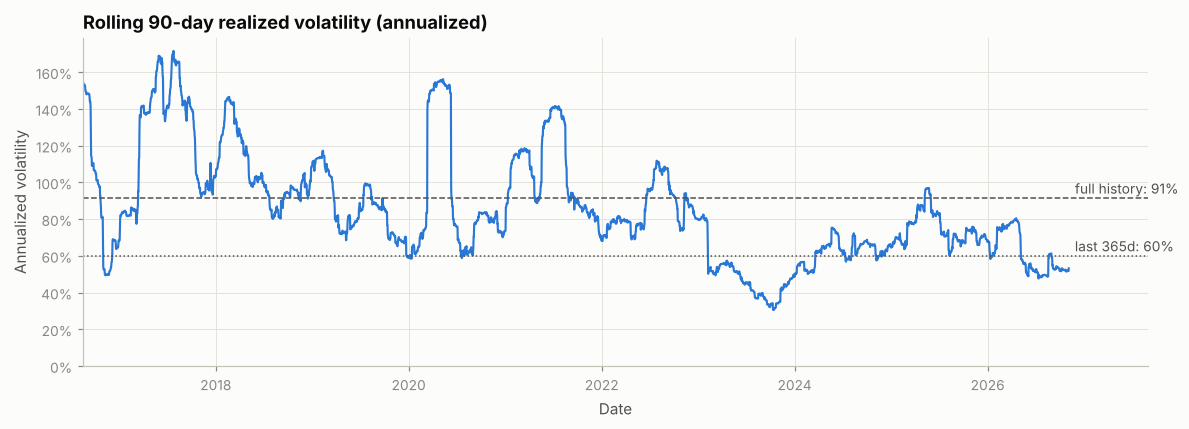

In [5]:
vol_full = log_ret.std() * np.sqrt(ANN)
vol_365 = log_ret.iloc[-365:].std() * np.sqrt(ANN)
vol_lookback = log_ret.iloc[-VOL_LOOKBACK_DAYS:].std() * np.sqrt(ANN)
SIGMA_ANNUAL = VOL_OVERRIDE if VOL_OVERRIDE is not None else vol_lookback

vol_table = pd.DataFrame({"annualized volatility": {
    f"Full history ({close.index.min().year}-today)": vol_full,
    "Last 365 days": vol_365,
    f"Last {VOL_LOOKBACK_DAYS} days (model default)": vol_lookback,
    "-> Used in simulations": SIGMA_ANNUAL,
}})
display(vol_table.style.format("{:.1%}"))

roll90 = log_ret.rolling(90).std() * np.sqrt(ANN)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(roll90.index, roll90, color=SERIES[0], lw=1.4)
for level, label, ls in [(vol_full, "full history", "--"), (vol_365, "last 365d", ":")]:
    ax.axhline(level, color=INK2, lw=1, ls=ls)
    ax.annotate(f"{label}: {level:.0%}", (roll90.index[-1], level), xytext=(4, 3),
                textcoords="offset points", color=INK2, fontsize=9, ha="left")
ax.yaxis.set_major_formatter(pct_fmt)
ax.set_ylim(0, None)
ax.set_title("Rolling 90-day realized volatility (annualized)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.set_xlim(roll90.dropna().index[0], roll90.index[-1] + pd.Timedelta(days=300))
plt.tight_layout()
plt.show()

### 2.2 Return distribution vs a fitted normal
If returns were normal, the histogram would follow the normal curve and the QQ plot would be a straight line. Fat tails show up as excess density far from zero on the log-scale histogram, and as the QQ points bending away from the line at both ends.

,value
Daily mean,0.1364%
Daily std,4.786%
Skewness (normal = 0),-0.40
Excess kurtosis (normal = 0),9.29
Jarque-Bera p-value,0.0e+00
Worst day,-55.1% (2020-03-12)
Best day,26.3% (2017-05-19)


,observed days,expected if normal
|move| > 3σ,75,10.32
|move| > 4σ,25,0.24
|move| > 5σ,8,0.00


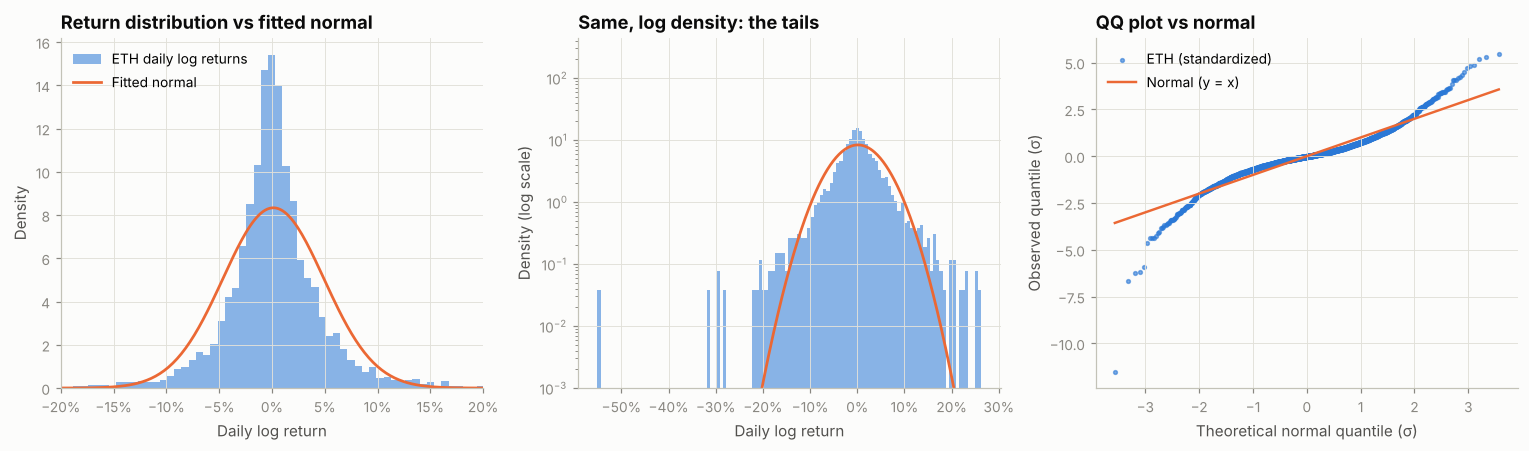

In [6]:
mu_hat, sd_hat = log_ret.mean(), log_ret.std()
skew = stats.skew(log_ret)
ex_kurt = stats.kurtosis(log_ret, fisher=True)
jb = stats.jarque_bera(log_ret)
z = (log_ret - mu_hat) / sd_hat

dist_table = pd.DataFrame({"value": {
    "Daily mean": f"{mu_hat:.4%}",
    "Daily std": f"{sd_hat:.3%}",
    "Skewness (normal = 0)": f"{skew:.2f}",
    "Excess kurtosis (normal = 0)": f"{ex_kurt:.2f}",
    "Jarque-Bera p-value": f"{jb.pvalue:.1e}",
    "Worst day": f"{log_ret.min():.1%} ({log_ret.idxmin().date()})",
    "Best day": f"{log_ret.max():.1%} ({log_ret.idxmax().date()})",
}})
tails = pd.DataFrame({
    "observed days": [(z.abs() > k).sum() for k in (3, 4, 5)],
    "expected if normal": [len(z) * 2 * stats.norm.sf(k) for k in (3, 4, 5)],
}, index=["|move| > 3σ", "|move| > 4σ", "|move| > 5σ"])
display(dist_table)
display(tails.style.format({"expected if normal": "{:.2f}"}))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
grid = np.linspace(log_ret.min(), log_ret.max(), 400)
bins = np.linspace(log_ret.min(), log_ret.max(), 120)
for ax, logy in zip(axes[:2], [False, True]):
    ax.hist(log_ret, bins=bins, density=True, color=SERIES[0], alpha=0.55, label="ETH daily log returns")
    ax.plot(grid, stats.norm.pdf(grid, mu_hat, sd_hat), color=SERIES[1], lw=1.8, label="Fitted normal")
    ax.xaxis.set_major_formatter(pct_fmt)
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density" + (" (log scale)" if logy else ""))
    if logy:
        ax.set_yscale("log")
        ax.set_ylim(1e-3, None)
        ax.set_title("Same, log density: the tails")
    else:
        ax.set_xlim(-0.2, 0.2)
        ax.set_title("Return distribution vs fitted normal")
        ax.legend(loc="upper left")
(osm, osr), (slope, intercept, _) = stats.probplot(z, dist="norm")
axes[2].scatter(osm, osr, s=6, color=SERIES[0], alpha=0.6, label="ETH (standardized)")
lim = np.array([osm.min(), osm.max()])
axes[2].plot(lim, lim, color=SERIES[1], lw=1.6, label="Normal (y = x)")
axes[2].set_title("QQ plot vs normal")
axes[2].set_xlabel("Theoretical normal quantile (σ)")
axes[2].set_ylabel("Observed quantile (σ)")
axes[2].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2.3 Drawdowns
Drawdown is the percentage fall from the highest close reached so far. The table lists the deepest distinct episodes. Each episode runs from a peak, down to its trough, and back to a recovery above the old peak, if that has happened yet.

,peak date,peak,trough date,trough,drawdown,days peak to trough,recovered,days to recover
1,2018-01-13,"$1,396",2018-12-14,$84,-94.0%,335,2021-02-02,781
2,2021-11-08,"$4,812",2022-06-18,$994,-79.4%,222,2025-08-22,"1,161"
3,2016-06-16,$21,2016-12-05,$7,-67.8%,172,2017-03-11,96
4,2025-08-22,"$4,831",2026-06-25,"$1,565",-67.6%,307,not yet,-
5,2017-06-12,$397,2017-07-16,$156,-60.8%,34,2017-11-23,130
6,2021-05-11,"$4,169",2021-07-20,"$1,788",-57.1%,70,2021-10-23,95
7,2021-02-19,"$1,960",2021-02-28,"$1,416",-27.8%,9,2021-04-01,32
8,2017-03-16,$46,2017-03-18,$34,-26.8%,2,2017-03-24,6


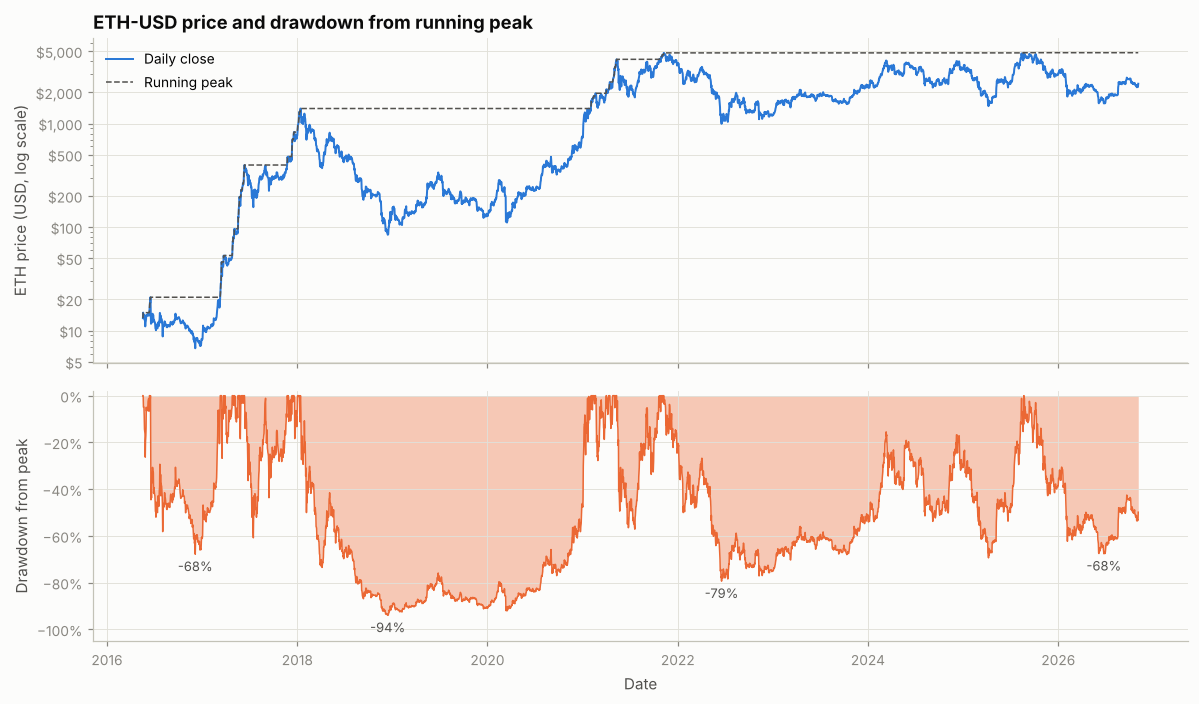

In [7]:
running_peak = close.cummax()
drawdown = close / running_peak - 1


def drawdown_episodes(close: pd.Series) -> pd.DataFrame:
    peak = close.cummax()
    dd = close / peak - 1
    new_high = dd == 0
    episode_id = new_high.cumsum()             # each new high starts a new episode
    rows = []
    for _, seg in dd.groupby(episode_id):
        if seg.min() >= 0:
            continue
        peak_date = seg.index[0]
        trough_date = seg.idxmin()
        after = close.loc[trough_date:]
        rec = after[after >= close.loc[peak_date]]
        rec_date = rec.index[0] if len(rec) else pd.NaT
        rows.append({"peak date": peak_date.date(), "peak": close.loc[peak_date],
                     "trough date": trough_date.date(), "trough": close.loc[trough_date],
                     "drawdown": seg.min(),
                     "days peak to trough": (trough_date - peak_date).days,
                     "recovered": rec_date.date() if pd.notna(rec_date) else "not yet",
                     "days to recover": (rec_date - trough_date).days if pd.notna(rec_date) else np.nan})
    return pd.DataFrame(rows).sort_values("drawdown").reset_index(drop=True)


dd_table = drawdown_episodes(close).head(8)
dd_table.index = dd_table.index + 1
display(dd_table.style.format({"peak": "${:,.0f}", "trough": "${:,.0f}", "drawdown": "{:.1%}",
                               "days to recover": "{:,.0f}"}, na_rep="-"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(close.index, close, color=SERIES[0], lw=1.3, label="Daily close")
ax1.plot(running_peak.index, running_peak, color=INK2, lw=1, ls="--", label="Running peak")
log_price_axis(ax1)
ax1.set_ylabel("ETH price (USD, log scale)")
ax1.set_title("ETH-USD price and drawdown from running peak")
ax1.legend(loc="upper left")
ax2.fill_between(drawdown.index, drawdown, 0, color=SERIES[1], alpha=0.35, lw=0)
ax2.plot(drawdown.index, drawdown, color=SERIES[1], lw=1)
ax2.yaxis.set_major_formatter(pct_fmt)
ax2.set_ylabel("Drawdown from peak")
ax2.set_xlabel("Date")
for _, row in dd_table.head(4).iterrows():
    d = pd.Timestamp(row["trough date"])
    ax2.annotate(f"{row['drawdown']:.0%}", (d, row["drawdown"]), xytext=(0, -11),
                 textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax2.set_ylim(-1.05, 0.02)
plt.tight_layout()
plt.show()

## 3. Simulation models

All four models have the same signature:

```python
simulate_x(s0, hist_returns, horizon, n_paths, rng, drift=DRIFT, vol=SIGMA_ANNUAL) -> ndarray of shape (n_paths, horizon + 1)
```

Column 0 of the output is today's price. To keep the comparison fair, every model is centered on the same daily log drift, `(drift - vol²/2) / 365`, and scaled to the same overall volatility, `vol`. With `DRIFT = 0` the expected price stays flat, while the median price drifts down slightly, which is how a volatile log-normal asset behaves. The models differ only in the shape of their returns and how returns cluster over time:

| Model | Daily returns | What it captures |
|---|---|---|
| **GBM** | i.i.d. normal | Baseline. Thin tails and no memory. |
| **Student-t** | i.i.d. Student-t, with degrees of freedom fitted to history | Fat tails, but no memory. |
| **Block bootstrap** | Resampled 10-day blocks of real, demeaned history | Real tail shape plus short-run volatility clustering. |
| **GMM regimes** | Normal within each regime, with a Markov chain switching between regimes | Long calm, bull and crash phases. Starts from the current regime. |

`hist_returns` is the full return history and determines each model's shape. `vol` comes from the last `VOL_LOOKBACK_DAYS` unless `VOL_OVERRIDE` is set.

In [8]:
def _daily_params(drift: float, vol_annual: float):
    """Daily log-return mean and std for an annual arithmetic drift and annual volatility."""
    mu_d = (drift - 0.5 * vol_annual ** 2) / ANN
    sd_d = vol_annual / np.sqrt(ANN)
    return mu_d, sd_d


def _resolve_vol(hist_returns, vol):
    return float(vol) if vol is not None else float(np.std(np.asarray(hist_returns, float), ddof=1) * np.sqrt(ANN))


def _to_paths(s0: float, log_returns: np.ndarray) -> np.ndarray:
    paths = np.empty((log_returns.shape[0], log_returns.shape[1] + 1))
    paths[:, 0] = s0
    paths[:, 1:] = s0 * np.exp(np.cumsum(log_returns, axis=1))
    return paths


def simulate_gbm(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None):
    """Geometric Brownian motion: i.i.d. normal log returns."""
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol))
    return _to_paths(s0, mu_d + sd_d * rng.standard_normal((n_paths, horizon)))


_T_FIT_CACHE = {}


def fit_student_t_df(hist_returns) -> float:
    r = np.asarray(hist_returns, float)
    key = (len(r), round(float(r.sum()), 10))
    if key not in _T_FIT_CACHE:
        z = (r - r.mean()) / r.std(ddof=1)
        nu, _, _ = stats.t.fit(z)
        _T_FIT_CACHE[key] = max(float(nu), 2.05)   # need nu > 2 for a finite variance
    return _T_FIT_CACHE[key]


def simulate_student_t(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None):
    """i.i.d. Student-t log returns: df fitted to history, scaled so the std equals `vol`."""
    nu = fit_student_t_df(hist_returns)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol))
    scale = sd_d * np.sqrt((nu - 2) / nu)          # Var[t_nu] = nu / (nu - 2)
    return _to_paths(s0, mu_d + scale * rng.standard_t(nu, size=(n_paths, horizon)))


def simulate_bootstrap(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, block=BLOCK_LENGTH):
    """Moving-block bootstrap of demeaned, re-scaled historical daily returns."""
    r = np.asarray(hist_returns, float)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol))
    pool = (r - r.mean()) / r.std(ddof=1) * sd_d + mu_d
    n_blocks = int(np.ceil(horizon / block))
    starts = rng.integers(0, len(pool) - block + 1, size=(n_paths, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_paths, -1)[:, :horizon]
    return _to_paths(s0, pool[idx])

### 3.4 GMM regime model
The regime model works in four steps:

1. **Features.** Compute two features for every day: the rolling 30-day mean return and the rolling 30-day volatility, both annualized and standardized.
2. **Fit.** Fit Gaussian mixtures with 2 and 3 components and keep the one with the lowest BIC. Each day is labelled with its most likely component. The regimes are named by their character: the lowest-volatility regime is **calm**, and the others are **bull** or **crash** by their mean return.
3. **Transitions.** Count day-to-day regime changes to estimate a daily Markov transition matrix.
4. **Simulate.** Each simulated path starts in today's regime and switches regimes according to the transition matrix. Each day's return is drawn from the current regime's normal distribution. Regime means and volatilities are shifted and scaled together, so the long-run mix matches the common drift and volatility while the gaps between regimes are preserved.

In [9]:
_REGIME_CACHE = {}


def _name_regimes(vol_feat: np.ndarray, mean_feat: np.ndarray) -> list:
    k = len(vol_feat)
    names = [None] * k
    calm = int(np.argmin(vol_feat))
    names[calm] = "calm"
    others = sorted([i for i in range(k) if i != calm], key=lambda i: mean_feat[i])
    if len(others) == 1:
        names[others[0]] = "crash" if mean_feat[others[0]] < 0 else "bull"
    else:
        names[others[0]], names[others[-1]] = "crash", "bull"
        for i in others[1:-1]:
            names[i] = "volatile"
    return names


def fit_regime_model(hist_returns, window=GMM_WINDOW, components=GMM_COMPONENTS, seed=SEED) -> dict:
    r = pd.Series(np.asarray(hist_returns, float),
                  index=hist_returns.index if isinstance(hist_returns, pd.Series) else None)
    key = (len(r), round(float(r.sum()), 10), window, tuple(components), seed)
    if key in _REGIME_CACHE:
        return _REGIME_CACHE[key]

    feats = pd.DataFrame({"mean_30d": r.rolling(window).mean() * ANN,
                          "vol_30d": r.rolling(window).std() * np.sqrt(ANN)}).dropna()
    X = StandardScaler().fit_transform(feats)
    fits = {k: GaussianMixture(k, covariance_type="full", n_init=5, random_state=seed).fit(X)
            for k in components}
    bic = {k: m.bic(X) for k, m in fits.items()}
    k = min(bic, key=bic.get)
    raw = fits[k].predict(X)

    vol_feat = np.array([feats["vol_30d"].to_numpy()[raw == j].mean() for j in range(k)])
    mean_feat = np.array([feats["mean_30d"].to_numpy()[raw == j].mean() for j in range(k)])
    raw_names = _name_regimes(vol_feat, mean_feat)
    order_pref = ["calm", "bull", "volatile", "crash"]
    order = sorted(range(k), key=lambda j: order_pref.index(raw_names[j]))
    remap = {old: new for new, old in enumerate(order)}
    labels = np.array([remap[j] for j in raw])
    names = [raw_names[j] for j in order]

    day_ret = r.loc[feats.index].to_numpy()
    mu = np.array([day_ret[labels == j].mean() for j in range(k)])
    sigma = np.array([day_ret[labels == j].std(ddof=1) for j in range(k)])

    counts = np.zeros((k, k))
    np.add.at(counts, (labels[:-1], labels[1:]), 1)
    P = counts / counts.sum(axis=1, keepdims=True)
    w, v = np.linalg.eig(P.T)
    pi = np.real(v[:, np.argmin(np.abs(w - 1))])
    pi = pi / pi.sum()

    fit = {"k": k, "bic": bic, "names": names, "labels": pd.Series(labels, index=feats.index),
           "features": feats, "mu": mu, "sigma": sigma, "P": P, "pi": pi,
           "current": int(labels[-1]), "share": np.bincount(labels, minlength=k) / len(labels)}
    _REGIME_CACHE[key] = fit
    return fit


def simulate_gmm_regime(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None):
    """Markov regime-switching returns; regimes from a GMM on rolling 30-day mean/vol features."""
    fit = fit_regime_model(hist_returns)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol))
    mu, sigma, P, pi = fit["mu"], fit["sigma"], fit["P"], fit["pi"]
    m = pi @ mu                                     # long-run (stationary) mixture mean
    v = pi @ (sigma ** 2 + mu ** 2) - m ** 2        # long-run mixture variance
    s = sd_d / np.sqrt(v)
    mu_adj, sig_adj = mu_d + (mu - m) * s, sigma * s
    cum_p = np.cumsum(P, axis=1)
    cum_p[:, -1] = 1.0
    state = np.full(n_paths, fit["current"])
    rets = np.empty((n_paths, horizon))
    for t in range(horizon):
        u = rng.random(n_paths)
        state = (u[:, None] > cum_p[state]).sum(axis=1)
        rets[:, t] = mu_adj[state] + sig_adj[state] * rng.standard_normal(n_paths)
    return _to_paths(s0, rets)

BIC by number of components: {2: 19430, 3: 19202} -> chose 3 regimes
Current regime (as of 2026-11-04): calm


,share of days,long-run share (stationary),avg 30d return (ann.),avg 30d vol (ann.),daily return mean,daily return std,expected stay (days)
calm,68.0%,68.4%,62.8%,64.0%,0.12%,3.50%,39
bull,10.9%,10.9%,715.3%,124.9%,1.62%,6.85%,10
crash,21.1%,20.7%,-337.3%,122.2%,-0.63%,6.54%,17


,to calm,to bull,to crash
from calm,0.974,0.012,0.014
from bull,0.078,0.898,0.024
from crash,0.045,0.013,0.943


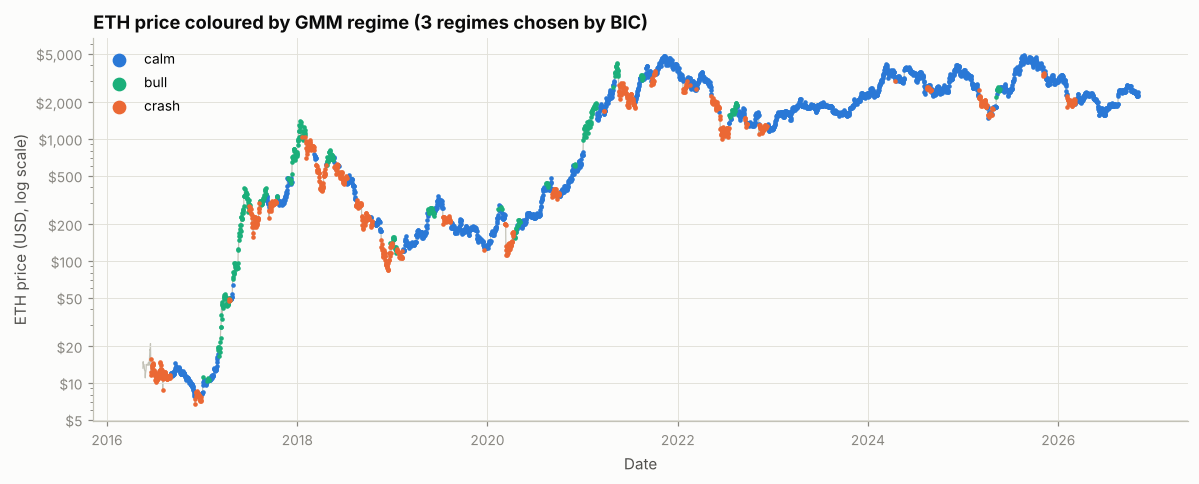

In [10]:
regimes = fit_regime_model(log_ret)
names = regimes["names"]
print("BIC by number of components:", {k: round(b) for k, b in regimes["bic"].items()},
      f"-> chose {regimes['k']} regimes")
print(f"Current regime (as of {regimes['labels'].index[-1].date()}): {names[regimes['current']]}")

regime_stats = pd.DataFrame({
    "share of days": regimes["share"],
    "long-run share (stationary)": regimes["pi"],
    "avg 30d return (ann.)": [regimes["features"]["mean_30d"][regimes["labels"] == j].mean() for j in range(regimes["k"])],
    "avg 30d vol (ann.)": [regimes["features"]["vol_30d"][regimes["labels"] == j].mean() for j in range(regimes["k"])],
    "daily return mean": regimes["mu"],
    "daily return std": regimes["sigma"],
    "expected stay (days)": 1 / (1 - np.diag(regimes["P"])),
}, index=names)
display(regime_stats.style.format({c: "{:.1%}" for c in regime_stats.columns[:4]} |
                                  {"daily return mean": "{:.2%}", "daily return std": "{:.2%}",
                                   "expected stay (days)": "{:.0f}"}))
trans = pd.DataFrame(regimes["P"], index=[f"from {n}" for n in names], columns=[f"to {n}" for n in names])
display(trans.style.format("{:.3f}").set_caption("Daily regime transition matrix"))

regime_colors = {"calm": SERIES[0], "crash": SERIES[1], "bull": SERIES[2], "volatile": SERIES[3]}
lab = regimes["labels"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(close.index, close, color=AXIS, lw=0.8, zorder=1)
for j, n in enumerate(names):
    d = lab.index[lab == j]
    ax.scatter(d, close.loc[d], s=4, color=regime_colors[n], label=n, zorder=2)
log_price_axis(ax)
ax.set_title(f"ETH price coloured by GMM regime ({regimes['k']} regimes chosen by BIC)")
ax.set_xlabel("Date")
ax.set_ylabel("ETH price (USD, log scale)")
ax.legend(loc="upper left", markerscale=4)
plt.tight_layout()
plt.show()

### 3.5 Run all models

In [11]:
MODELS = {
    "GBM": simulate_gbm,
    "Student-t": simulate_student_t,
    "Block bootstrap": simulate_bootstrap,
    "GMM regimes": simulate_gmm_regime,
}
MODEL_COLORS = dict(zip(MODELS, SERIES))

t0 = time.time()
paths = {name: fn(S0, log_ret, HORIZON_DAYS, N_PATHS, rng_for(name), drift=DRIFT, vol=SIGMA_ANNUAL)
         for name, fn in MODELS.items()}
print(f"Simulated {len(MODELS)} models × {N_PATHS:,} paths × {HORIZON_DAYS} days in {time.time() - t0:.1f}s")
print(f"Start price ${S0:,.2f} | drift {DRIFT:.0%} | volatility {SIGMA_ANNUAL:.1%} | "
      f"Student-t df = {fit_student_t_df(log_ret):.2f}")

sanity = pd.DataFrame({name: {
    "realized ann. vol of simulated returns": np.diff(np.log(p), axis=1).std() * np.sqrt(ANN),
    "mean end price / S0": p[:, -1].mean() / S0,
    "median end price / S0": np.median(p[:, -1]) / S0,
} for name, p in paths.items()})
display(sanity.style.format("{:.3f}"))

Simulated 4 models × 10,000 paths × 365 days in 0.8s
Start price $2,416.00 | drift 0% | volatility 68.8% | Student-t df = 2.41


,GBM,Student-t,Block bootstrap,GMM regimes
realized ann. vol of simulated returns,0.688,0.702,0.689,0.684
mean end price / S0,0.999,0.988,1.016,1.062
median end price / S0,0.780,0.795,0.780,0.785


## 4. Outputs

### 4.1 Fan charts
The shaded bands show the 5–95th and 25–75th percentiles of simulated prices on each day, and the line is the median path. The price axis is logarithmic, so equal percentage moves take equal vertical space.

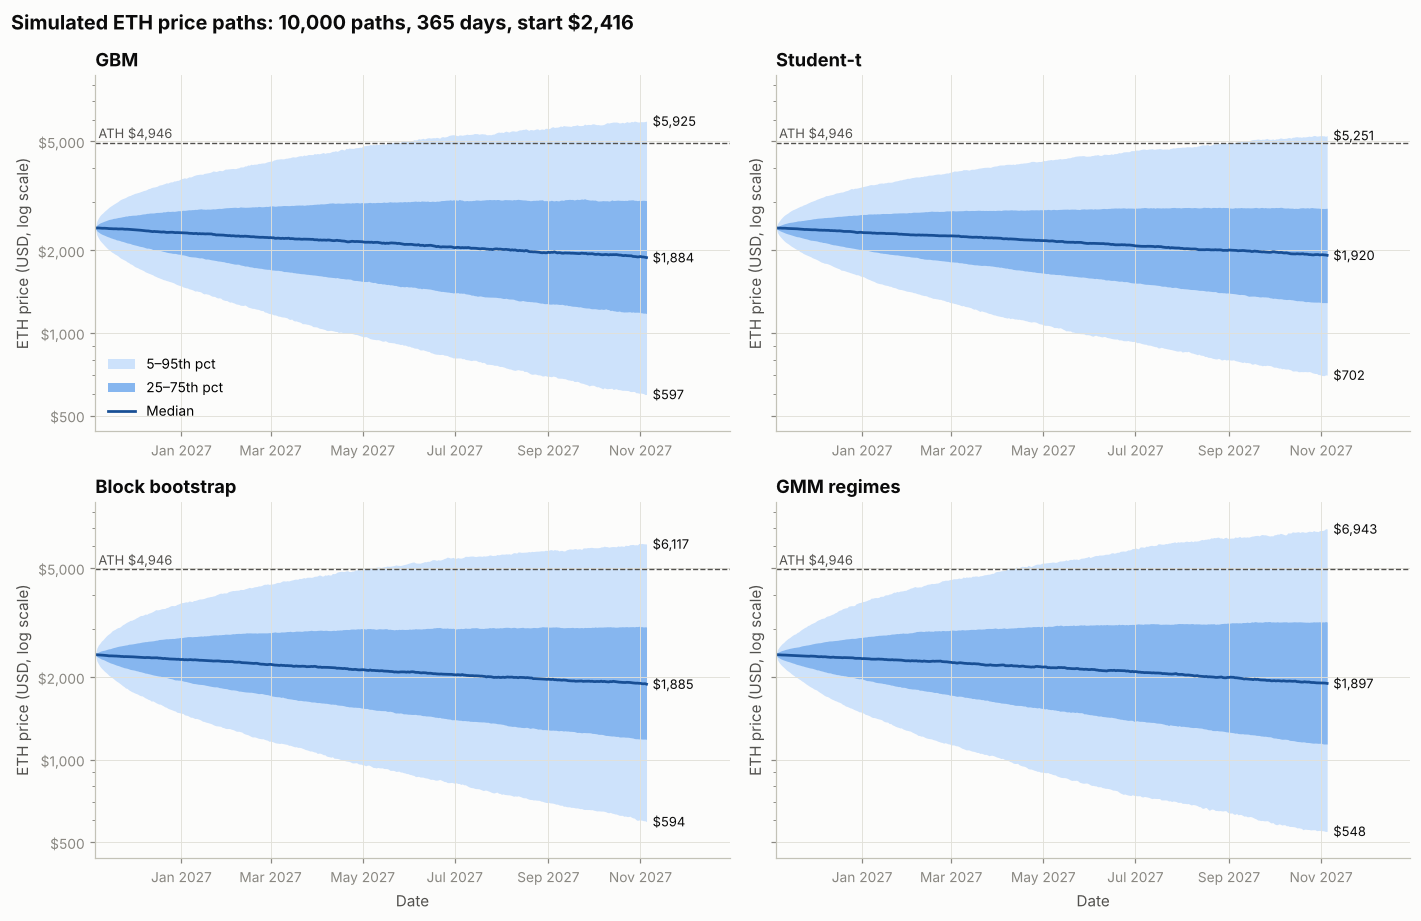

In [12]:
sim_dates = pd.date_range(TODAY, periods=HORIZON_DAYS + 1, freq="D")


def fan_chart(ax, p, title):
    q = np.percentile(p, PERCENTILES, axis=0)
    ax.fill_between(sim_dates, q[0], q[4], color=BLUE_RAMP["band_outer"], lw=0, label="5–95th pct")
    ax.fill_between(sim_dates, q[1], q[3], color=BLUE_RAMP["band_inner"], lw=0, label="25–75th pct")
    ax.plot(sim_dates, q[2], color=BLUE_RAMP["median"], lw=1.8, label="Median")
    ax.axhline(ATH_PRICE, color=INK2, lw=0.9, ls="--")
    ax.annotate(f"ATH ${ATH_PRICE:,}", (sim_dates[2], ATH_PRICE), xytext=(0, 3),
                textcoords="offset points", fontsize=8.5, color=INK2)
    for qi, v in zip([0, 2, 4], [q[0, -1], q[2, -1], q[4, -1]]):
        ax.annotate(fmt_usd(v), (sim_dates[-1], v), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK)
    log_price_axis(ax)
    ax.set_title(title)
    ax.set_ylabel("ETH price (USD, log scale)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))


fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for ax, (name, p) in zip(axes.flat, paths.items()):
    fan_chart(ax, p, name)
for ax in axes[1]:
    ax.set_xlabel("Date")
axes[0, 0].legend(loc="lower left")
ylo = min(np.percentile(p[:, 1:], 5, axis=0).min() for p in paths.values()) * 0.8
yhi = max(np.percentile(p[:, 1:], 95, axis=0).max() for p in paths.values()) * 1.25
axes[0, 0].set_ylim(ylo, yhi)
for ax in axes.flat:
    ax.set_xlim(sim_dates[0], sim_dates[-1] + pd.Timedelta(days=55))
fig.suptitle(f"Simulated ETH price paths: {N_PATHS:,} paths, {HORIZON_DAYS} days, start ${S0:,.0f}",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

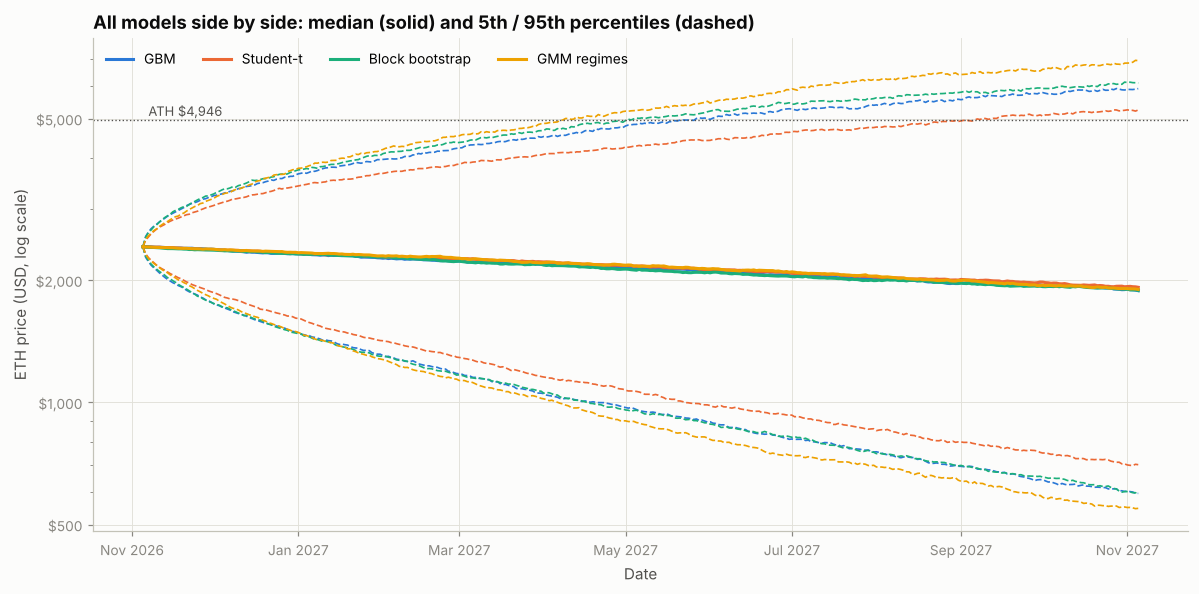

In [13]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for name, p in paths.items():
    c = MODEL_COLORS[name]
    q = np.percentile(p, [5, 50, 95], axis=0)
    ax.plot(sim_dates, q[1], color=c, lw=2, label=f"{name}")
    ax.plot(sim_dates, q[0], color=c, lw=1.1, ls="--")
    ax.plot(sim_dates, q[2], color=c, lw=1.1, ls="--")
ax.axhline(ATH_PRICE, color=INK2, lw=0.9, ls=":")
ax.annotate(f"ATH ${ATH_PRICE:,}", (sim_dates[2], ATH_PRICE), xytext=(0, 3), textcoords="offset points",
            fontsize=8.5, color=INK2)
log_price_axis(ax)
ax.set_title("All models side by side: median (solid) and 5th / 95th percentiles (dashed)")
ax.set_xlabel("Date")
ax.set_ylabel("ETH price (USD, log scale)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=4)
plt.tight_layout()
plt.show()

### 4.2 End-price percentiles and implied market cap
Implied market cap is the price multiplied by today's circulating supply. Supply is held constant here, although in reality ETH issuance and burning change it slightly.

In [14]:
def end_percentiles(p: np.ndarray) -> pd.DataFrame:
    v = np.percentile(p[:, -1], PERCENTILES)
    return pd.DataFrame({"price": v, "market cap": v * SUPPLY, "vs today": v / S0 - 1},
                        index=[f"P{q}" for q in PERCENTILES])


pct_tables = {name: end_percentiles(p) for name, p in paths.items()}
end_table = pd.concat(pct_tables, axis=1)
end_table.columns.names = ["model", ""]
fmt = {}
for name in MODELS:
    fmt |= {(name, "price"): "${:,.0f}", (name, "market cap"): lambda x: fmt_bn(x), (name, "vs today"): "{:+.0%}"}
print(f"End price after {HORIZON_DAYS} days (start ${S0:,.0f}, market cap {fmt_bn(S0 * SUPPLY)})")
display(end_table.style.format(fmt))

End price after 365 days (start $2,416, market cap $295B)


### 4.3 Probability of ending above and touching price levels
- **Ends above** is the share of paths whose final price is above the level.
- **Touches** is the share of paths that reach the level on at least one day during the horizon. This is computed from the paths as a first-passage probability. Levels above today's price are touched by rising to them, and levels below by falling to them.

Paths are sampled at daily closes, so intraday wicks are missed and touch probabilities are slightly understated.

Probability of ENDING ABOVE each level after 365 days


,GBM,Student-t,Block bootstrap,GMM regimes
"$1,000",81.8%,86.0%,81.9%,79.9%
"$1,500",63.2%,66.1%,63.2%,62.6%
"$2,000",46.7%,46.9%,46.8%,47.2%
"$3,000",25.8%,22.2%,25.7%,27.4%
"$4,946",8.4%,6.0%,8.7%,10.8%
"$8,000",2.0%,1.4%,2.4%,3.2%
"$10,000",0.8%,0.7%,1.2%,1.6%


Probability of TOUCHING each level at any point within 365 days


,GBM,Student-t,Block bootstrap,GMM regimes
"$1,000 (fall to)",29.6%,21.2%,29.8%,31.8%
"$1,500 (fall to)",59.0%,51.6%,59.6%,59.4%
"$2,000 (fall to)",83.3%,80.5%,83.5%,82.5%
"$3,000 (rise to)",63.7%,55.5%,61.9%,64.9%
"$4,946 (rise to)",18.9%,12.3%,20.1%,22.5%
"$8,000 (rise to)",4.3%,2.4%,5.0%,6.6%
"$10,000 (rise to)",1.8%,1.2%,2.4%,3.5%


Median days to first touch (among paths that touch)


,GBM,Student-t,Block bootstrap,GMM regimes
"$1,000 (fall to)",224,244,222,218
"$1,500 (fall to)",131,168,133,134
"$2,000 (fall to)",43,64,49,51
"$3,000 (rise to)",52,77,59,61
"$4,946 (rise to)",194,222,185,178
"$8,000 (rise to)",272,257,255,251
"$10,000 (rise to)",295,242,275,275


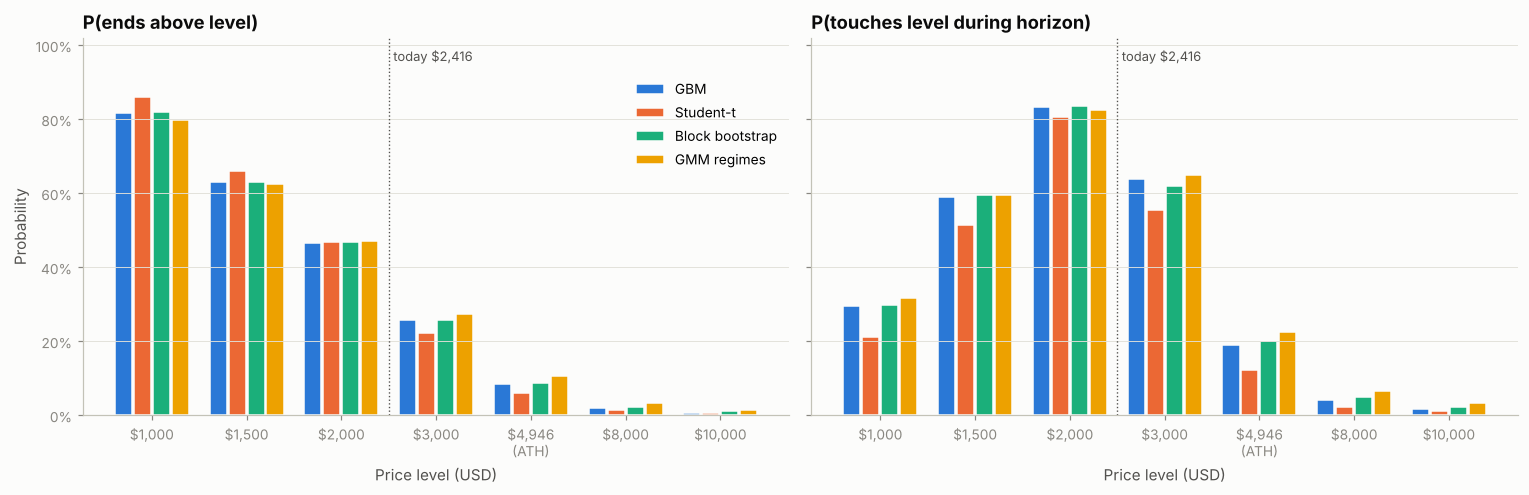

In [15]:
def threshold_probs(p: np.ndarray, thresholds) -> pd.DataFrame:
    s0, end = p[0, 0], p[:, -1]
    pmax, pmin = p[:, 1:].max(axis=1), p[:, 1:].min(axis=1)
    rows = {}
    for k in thresholds:
        touched = (pmax >= k) if k >= s0 else (pmin <= k)
        hit_day = np.where(touched, np.argmax((p[:, 1:] >= k) if k >= s0 else (p[:, 1:] <= k), axis=1) + 1, np.nan)
        rows[f"${k:,}"] = {"direction": "rise to" if k >= s0 else "fall to",
                          "P(ends above)": (end > k).mean(),
                          "P(touches)": touched.mean(),
                          "median days to first touch": np.nanmedian(hit_day) if touched.any() else np.nan}
    return pd.DataFrame(rows).T


prob_tables = {name: threshold_probs(p, THRESHOLDS) for name, p in paths.items()}
above = pd.DataFrame({n: t["P(ends above)"] for n, t in prob_tables.items()}).astype(float)
touch = pd.DataFrame({n: t["P(touches)"] for n, t in prob_tables.items()}).astype(float)
direction = prob_tables["GBM"]["direction"]
touch.index = [f"{lvl} ({d})" for lvl, d in zip(touch.index, direction)]
print(f"Probability of ENDING ABOVE each level after {HORIZON_DAYS} days")
display(above.style.format("{:.1%}"))
print(f"Probability of TOUCHING each level at any point within {HORIZON_DAYS} days")
display(touch.style.format("{:.1%}"))
days_to_touch = pd.DataFrame({n: t["median days to first touch"] for n, t in prob_tables.items()}).astype(float)
days_to_touch.index = touch.index
print("Median days to first touch (among paths that touch)")
display(days_to_touch.style.format("{:.0f}", na_rep="-"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
x = np.arange(len(THRESHOLDS))
w = 0.8 / len(MODELS)
for ax, df, title in [(axes[0], above, "P(ends above level)"), (axes[1], touch, "P(touches level during horizon)")]:
    for i, name in enumerate(MODELS):
        ax.bar(x + (i - (len(MODELS) - 1) / 2) * w, df[name].to_numpy(), width=w * 0.9,
               color=MODEL_COLORS[name], label=name, edgecolor=SURFACE, linewidth=1)
    ax.set_xticks(x, [f"${k:,}" + ("\n(ATH)" if k == ATH_PRICE else "") for k in THRESHOLDS])
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.set_xlabel("Price level (USD)")
    ax.grid(axis="x", visible=False)
    ax.axvline(np.searchsorted(THRESHOLDS, S0) - 0.5, color=INK2, lw=0.9, ls=":")
    ax.annotate(f"today ${S0:,.0f}", (np.searchsorted(THRESHOLDS, S0) - 0.5, 1.0), xytext=(3, -2),
                textcoords="offset points", fontsize=8.5, color=INK2, va="top")
axes[0].set_ylabel("Probability")
axes[0].legend(loc="upper right", bbox_to_anchor=(1.0, 0.92))
plt.tight_layout()
plt.show()

### 4.4 Maximum drawdown along the path
For each path, the maximum drawdown is the deepest peak-to-trough fall during the horizon, counting today's price as the first peak.

,GBM,Student-t,Block bootstrap,GMM regimes
expected max drawdown (mean),-57.9%,-51.3%,-57.7%,-58.9%
median,-57.6%,-50.6%,-57.5%,-58.9%
P(drawdown worse than -30%),98.1%,91.9%,97.8%,97.5%
P(drawdown worse than -50%),67.9%,51.2%,68.2%,68.3%
5th percentile (bad case),-82.1%,-77.7%,-81.8%,-83.9%


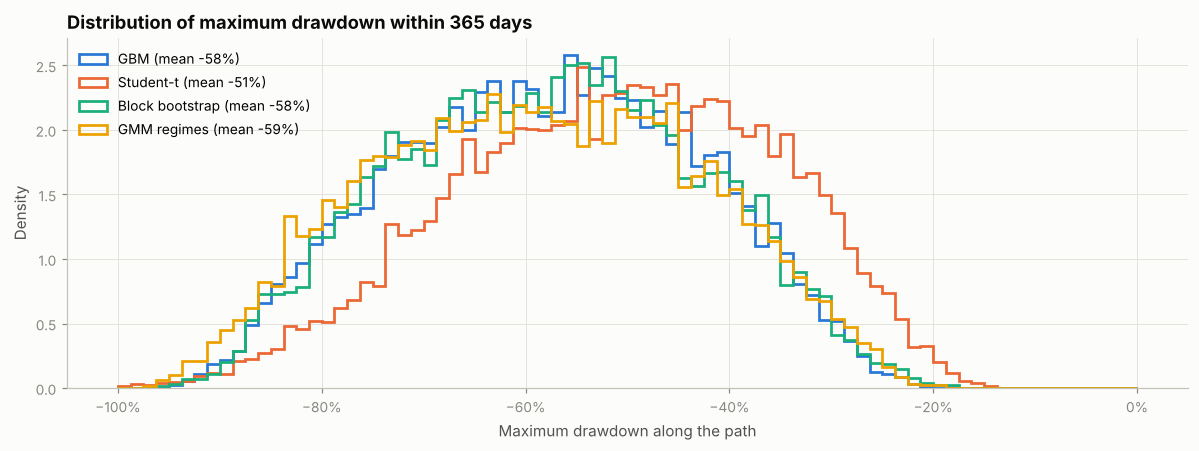

In [16]:
def max_drawdown(p: np.ndarray) -> np.ndarray:
    return (p / np.maximum.accumulate(p, axis=1) - 1).min(axis=1)


mdd = {name: max_drawdown(p) for name, p in paths.items()}
mdd_table = pd.DataFrame({name: {
    "expected max drawdown (mean)": v.mean(),
    "median": np.median(v),
    "P(drawdown worse than -30%)": (v < -0.30).mean(),
    "P(drawdown worse than -50%)": (v < -0.50).mean(),
    "5th percentile (bad case)": np.percentile(v, 5),
} for name, v in mdd.items()})
display(mdd_table.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(11, 4.2))
bins = np.linspace(-1, 0, 81)
for name, v in mdd.items():
    ax.hist(v, bins=bins, histtype="step", lw=1.8, color=MODEL_COLORS[name], density=True,
            label=f"{name} (mean {v.mean():.0%})")
ax.xaxis.set_major_formatter(pct_fmt)
ax.set_title(f"Distribution of maximum drawdown within {HORIZON_DAYS} days")
ax.set_xlabel("Maximum drawdown along the path")
ax.set_ylabel("Density")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Strategy tester
Each strategy starts with **$1 of capital** on day 0, and its outcome is the **portfolio value on the final day**. All trades execute at the daily close, with no fees, slippage or interest on cash.

- **Hold:** invest everything on day 0 and do nothing else.
- **Sell ladder:** invest everything on day 0. Sell 25% of the original ETH the first time the price closes at or above 1.5× entry, another 25% at 2×, and another 25% at 3×. Proceeds are held as cash.
- **DCA on dips:** invest 50% on day 0 and split the other 50% into 5 cash tranches. Buy one tranche each time the price closes 20% or more below its running peak. After each buy the peak resets to that day's price, so the next tranche needs a further 20% fall. Unspent cash stays as cash.

Because the DCA rule keeps part of its capital out of the market, it gives up upside in rallies in exchange for protection in sell-offs.

Final value of $1 after the horizon


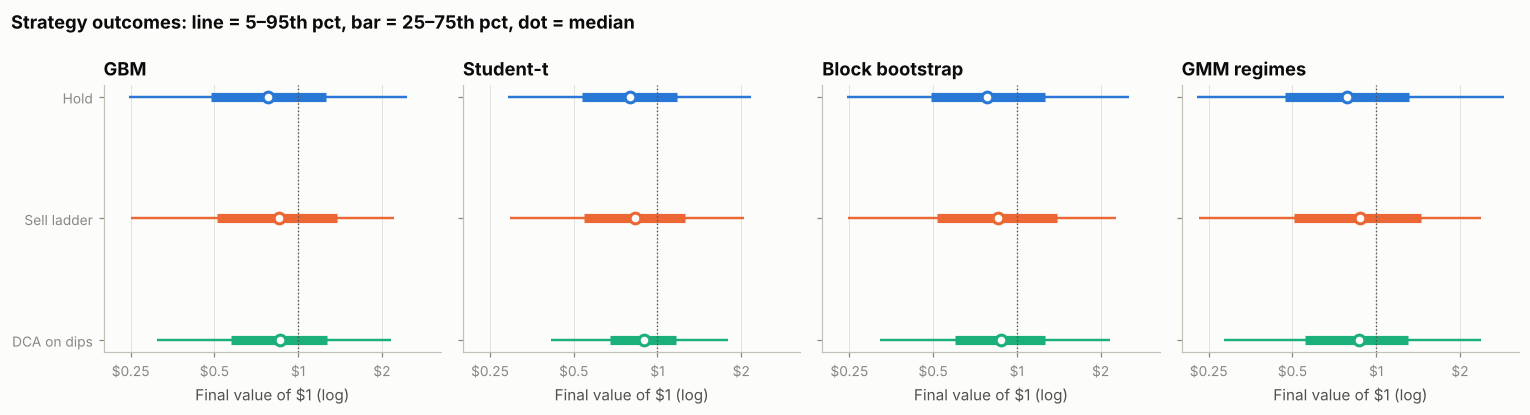

In [17]:
def strat_hold(p):
    return p[:, -1] / p[:, 0]


def strat_ladder(p, ladder=LADDER):
    rel = p / p[:, :1]                              # price relative to entry; 1 unit of ETH = $1 at entry
    eth = np.ones(len(p))
    cash = np.zeros(len(p))
    ar = np.arange(len(p))
    for mult, frac in ladder:
        hit = (rel >= mult).any(axis=1)
        first = np.argmax(rel >= mult, axis=1)
        cash += np.where(hit, frac * rel[ar, first], 0.0)
        eth -= np.where(hit, frac, 0.0)
    return cash + eth * rel[:, -1]


def strat_dca(p, initial=DCA_INITIAL_FRACTION, n_tranches=DCA_N_TRANCHES, drop=DCA_TRIGGER_DROP):
    rel = p / p[:, :1]
    tranche = (1 - initial) / n_tranches
    eth = np.full(len(p), initial)                  # in entry-price units
    cash = np.full(len(p), 1 - initial)
    left = np.full(len(p), n_tranches)
    peak = rel[:, 0].copy()
    for t in range(1, rel.shape[1]):
        price = rel[:, t]
        peak = np.maximum(peak, price)
        buy = (price <= (1 - drop) * peak) & (left > 0)
        eth[buy] += tranche / price[buy]
        cash[buy] -= tranche
        left[buy] -= 1
        peak[buy] = price[buy]
    return cash + eth * rel[:, -1]


STRATEGIES = {"Hold": strat_hold, "Sell ladder": strat_ladder, "DCA on dips": strat_dca}
STRAT_COLORS = dict(zip(STRATEGIES, SERIES))

strategy_rows, strategy_values = [], {}
for model, p in paths.items():
    hold = strat_hold(p)
    for sname, fn in STRATEGIES.items():
        v = fn(p)
        strategy_values[(model, sname)] = v
        strategy_rows.append({"model": model, "strategy": sname,
                              "P5": np.percentile(v, 5), "median": np.median(v), "P95": np.percentile(v, 95),
                              "mean": v.mean(),
                              "P(beats hold)": np.nan if sname == "Hold" else (v > hold).mean()})
strategy_table = pd.DataFrame(strategy_rows).set_index(["model", "strategy"])
print("Final value of $1 after the horizon")
display(strategy_table.style.format({"P5": "${:.2f}", "median": "${:.2f}", "P95": "${:.2f}", "mean": "${:.2f}",
                                     "P(beats hold)": "{:.1%}"}, na_rep="-"))

fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 3.8), sharex=True, sharey=True)
for ax, model in zip(axes, MODELS):
    for i, sname in enumerate(STRATEGIES):
        v = strategy_values[(model, sname)]
        p5, p25, p50, p75, p95 = np.percentile(v, [5, 25, 50, 75, 95])
        y = len(STRATEGIES) - 1 - i
        c = STRAT_COLORS[sname]
        ax.hlines(y, p5, p95, color=c, lw=1.6)
        ax.hlines(y, p25, p75, color=c, lw=6)
        ax.plot(p50, y, "o", color=SURFACE, mec=c, mew=2, ms=7)
    ax.axvline(1.0, color=INK2, lw=0.9, ls=":")
    ax.set_title(model)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.25, 0.5, 1, 2, 4]))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_xlabel("Final value of $1 (log)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(STRATEGIES)), list(STRATEGIES)[::-1])
fig.suptitle("Strategy outcomes: line = 5–95th pct, bar = 25–75th pct, dot = median",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

## 6. Calibration check
Do the models' intervals contain what actually happened? The backtest works as follows:

1. Pick a historical start date. Use only the data available up to that date: the trailing `VOL_LOOKBACK_DAYS` for volatility, and the full history so far for the bootstrap pool.
2. Simulate 1-year paths from that date's close.
3. Check whether the realized close one year later fell inside the model's central **68%** interval (16th–84th percentile) and **95%** interval (2.5th–97.5th percentile).

This is repeated every `CAL_STEP_DAYS` days. Coverage close to 68% and 95% means the model is well calibrated. Coverage **below** nominal means the model is **overconfident**, with intervals that are too narrow. Coverage **above** nominal means it is **underconfident**, with intervals that are too wide.

The windows overlap heavily, so consecutive checks are not independent. The effective sample is closer to the number of non-overlapping years, so treat these rates as indicative rather than precise.

In [18]:
CAL_MODELS = {"GBM": simulate_gbm, "Block bootstrap": simulate_bootstrap}
min_hist = max(VOL_LOOKBACK_DAYS, 365) if VOL_OVERRIDE is None else 365
first_start = log_ret.index[min_hist - 1]
last_start = close.index[-1] - pd.Timedelta(days=CAL_HORIZON_DAYS)
cal_starts = pd.date_range(first_start, last_start, freq=f"{CAL_STEP_DAYS}D")

t0 = time.time()
cal_rows = []
for name, fn in CAL_MODELS.items():
    rng = rng_for(f"calibration/{name}")
    for d in cal_starts:
        hist = log_ret.loc[:d]
        vol = VOL_OVERRIDE if VOL_OVERRIDE is not None else hist.iloc[-VOL_LOOKBACK_DAYS:].std() * np.sqrt(ANN)
        s_start = close.loc[d]
        ends = fn(s_start, hist, CAL_HORIZON_DAYS, CAL_N_PATHS, rng, drift=DRIFT, vol=vol)[:, -1]
        lo95, lo68, hi68, hi95 = np.percentile(ends, [2.5, 16, 84, 97.5])
        realized = close.loc[d + pd.Timedelta(days=CAL_HORIZON_DAYS)]
        cal_rows.append({"model": name, "start": d, "start price": s_start, "realized": realized, "vol": vol,
                         "lo95": lo95, "lo68": lo68, "hi68": hi68, "hi95": hi95})
cal = pd.DataFrame(cal_rows)
print(f"{len(cal_starts)} start dates from {cal_starts[0].date()} to {cal_starts[-1].date()}, "
      f"{CAL_N_PATHS:,} paths each ({time.time() - t0:.0f}s)")


def verdict(cov, nominal, tol=0.05):
    if cov < nominal - tol:
        return "overconfident (intervals too narrow)"
    if cov > nominal + tol:
        return "underconfident (intervals too wide)"
    return "roughly calibrated"


coverage = {}
for name, g in cal.groupby("model", sort=False):
    in68 = ((g["realized"] >= g["lo68"]) & (g["realized"] <= g["hi68"])).mean()
    in95 = ((g["realized"] >= g["lo95"]) & (g["realized"] <= g["hi95"])).mean()
    coverage[name] = {"68% interval coverage": in68, "  missed above (68%)": (g["realized"] > g["hi68"]).mean(),
                      "  missed below (68%)": (g["realized"] < g["lo68"]).mean(),
                      "95% interval coverage": in95, "  missed above (95%)": (g["realized"] > g["hi95"]).mean(),
                      "  missed below (95%)": (g["realized"] < g["lo95"]).mean()}
coverage = pd.DataFrame(coverage)
display(coverage.style.format("{:.1%}"))
for name in CAL_MODELS:
    c68, c95 = coverage.loc["68% interval coverage", name], coverage.loc["95% interval coverage", name]
    print(f"{name:16s} 68% band: {c68:5.1%} coverage -> {verdict(c68, 0.68)}")
    print(f"{'':16s} 95% band: {c95:5.1%} coverage -> {verdict(c95, 0.95)}")
    up, down = coverage.loc["  missed above (95%)", name], coverage.loc["  missed below (95%)", name]
    if up + down > 0:
        side = "above" if up > down else "below"
        print(f"{'':16s} {max(up, down) / (up + down):.0%} of 95%-band misses were {side} the band "
              f"-> {'reality beat the zero-drift centre' if side == 'above' else 'reality fell further than modelled'}")

390 start dates from 2018-05-18 to 2025-10-31, 2,000 paths each (9s)


,GBM,Block bootstrap
68% interval coverage,63.6%,68.5%
missed above (68%),36.2%,31.5%
missed below (68%),0.3%,0.0%
95% interval coverage,85.6%,86.4%
missed above (95%),14.4%,13.6%
missed below (95%),0.0%,0.0%


GBM              68% band: 63.6% coverage -> roughly calibrated
                 95% band: 85.6% coverage -> overconfident (intervals too narrow)
                 100% of 95%-band misses were above the band -> reality beat the zero-drift centre
Block bootstrap  68% band: 68.5% coverage -> roughly calibrated
                 95% band: 86.4% coverage -> overconfident (intervals too narrow)
                 100% of 95%-band misses were above the band -> reality beat the zero-drift centre


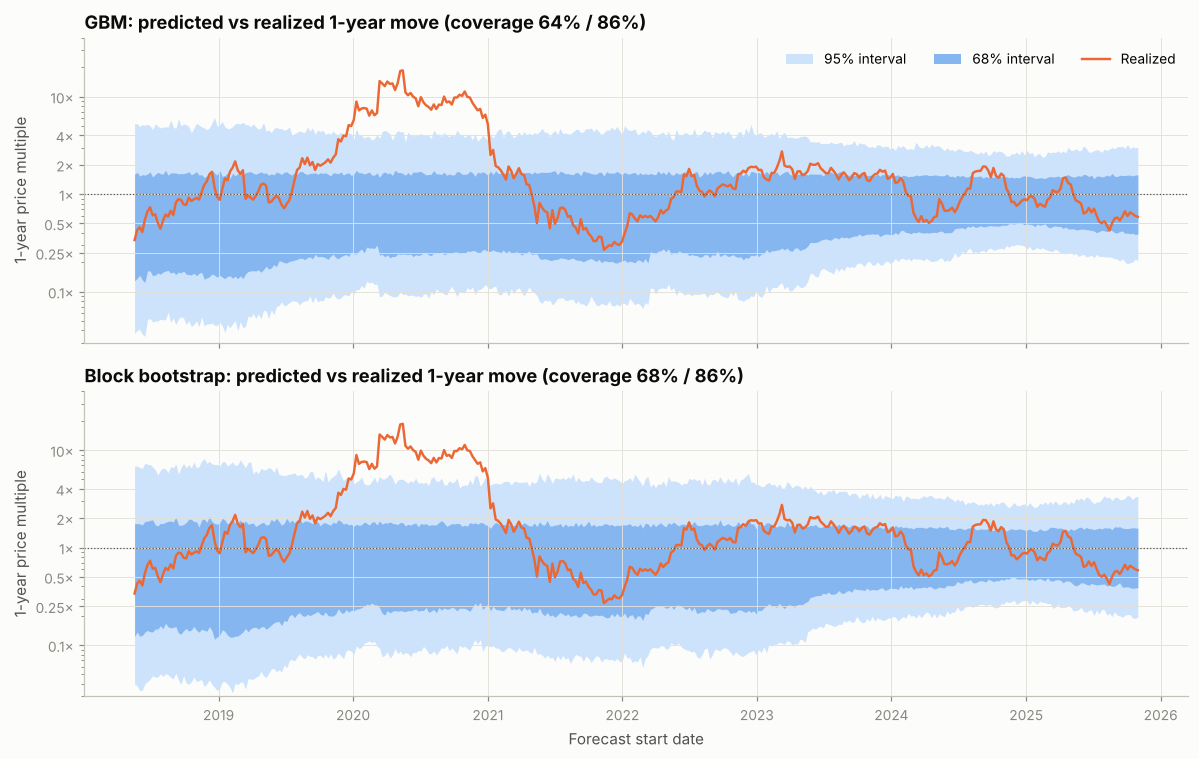

In [19]:
fig, axes = plt.subplots(len(CAL_MODELS), 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, name in zip(axes, CAL_MODELS):
    g = cal[cal["model"] == name]
    x = g["start"]
    ax.fill_between(x, g["lo95"] / g["start price"], g["hi95"] / g["start price"],
                    color=BLUE_RAMP["band_outer"], lw=0, label="95% interval")
    ax.fill_between(x, g["lo68"] / g["start price"], g["hi68"] / g["start price"],
                    color=BLUE_RAMP["band_inner"], lw=0, label="68% interval")
    ax.plot(x, g["realized"] / g["start price"], color=SERIES[1], lw=1.6, label="Realized")
    ax.axhline(1, color=INK2, lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([0.1, 0.25, 0.5, 1, 2, 4, 10]))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_ylabel("1-year price multiple")
    ax.set_ylim(0.03, 40)
    c68, c95 = coverage.loc["68% interval coverage", name], coverage.loc["95% interval coverage", name]
    ax.set_title(f"{name}: predicted vs realized 1-year move (coverage {c68:.0%} / {c95:.0%})")
axes[0].legend(loc="upper right", ncols=3)
axes[-1].set_xlabel("Forecast start date")
plt.tight_layout()
plt.show()

## 7. Key numbers from this run
This cell recomputes the headline figures, so they stay current when the notebook is rerun.

In [20]:
lines = [f"As of {snapshot['fetched_at_utc'][:10]}: ETH ${S0:,.0f}, supply {SUPPLY / 1e6:,.1f}M, "
         f"market cap {fmt_bn(S0 * SUPPLY)}. Volatility used: {SIGMA_ANNUAL:.0%}, drift {DRIFT:.0%}.",
         f"Horizon {HORIZON_DAYS} days, {N_PATHS:,} paths, seed {SEED}.", ""]
for name in MODELS:
    t = pct_tables[name]
    lines.append(f"{name:16s} median {fmt_usd(t.loc['P50', 'price'])}, 90% range "
                 f"{fmt_usd(t.loc['P5', 'price'])}–{fmt_usd(t.loc['P95', 'price'])} | "
                 f"P(end > ATH) {above.loc[f'${ATH_PRICE:,}', name]:.0%}, "
                 f"P(touch ATH) {touch.iloc[THRESHOLDS.index(ATH_PRICE)][name]:.0%}, "
                 f"P(touch $1,000) {touch.iloc[0][name]:.0%} | E[max DD] {mdd[name].mean():.0%}")
lines.append("")
for name in CAL_MODELS:
    lines.append(f"Calibration {name:16s} 68%: {coverage.loc['68% interval coverage', name]:.0%}, "
                 f"95%: {coverage.loc['95% interval coverage', name]:.0%}")
print("\n".join(lines))

As of 2026-11-05: ETH $2,416, supply 122.2M, market cap $295B. Volatility used: 69%, drift 0%.
Horizon 365 days, 10,000 paths, seed 42.

GBM              median $1,884, 90% range $597–$5,925 | P(end > ATH) 8%, P(touch ATH) 19%, P(touch $1,000) 30% | E[max DD] -58%
Student-t        median $1,920, 90% range $702–$5,251 | P(end > ATH) 6%, P(touch ATH) 12%, P(touch $1,000) 21% | E[max DD] -51%
Block bootstrap  median $1,885, 90% range $594–$6,117 | P(end > ATH) 9%, P(touch ATH) 20%, P(touch $1,000) 30% | E[max DD] -58%
GMM regimes      median $1,897, 90% range $548–$6,943 | P(end > ATH) 11%, P(touch ATH) 23%, P(touch $1,000) 32% | E[max DD] -59%

Calibration GBM              68%: 64%, 95%: 86%
Calibration Block bootstrap  68%: 68%, 95%: 86%


## 8. Summary and limitations

*These figures come from the run on 2026-11-05: ETH at about $2,420, a market cap of about $295B, and 69% volatility from the last two years, with zero drift. The printout in section 7 is recomputed on every run, so check it if you have rerun the notebook.*

**What the simulations say**

- **The typical outcome is a bit lower, but the average is flat.** With no drift assumed, the median price after one year is about **$1,900**, below today's price. This is not a bearish call. For an asset this volatile, the expected price stays roughly where it is today, but more than half the paths end lower, while a minority of very large gains pull the average up.
- **The range is very wide.** The middle 50% of outcomes falls between roughly **$1,150 and $3,100**, and the 90% range runs from about **$550 to $7,000**. In implied market cap that is roughly $70B to $850B.
- **Key levels:**
  - **All-time high ($4,946):** about a **6–11%** chance of ending the year above it, and about **12–23%** of touching it at some point.
  - **$10,000:** about 1–2%.
  - **Downside:** roughly a **20–30%** chance of falling to **$1,000** at some point, and about **80%** of trading below $2,000 at some point during the year.
- **Expect large swings along the way.** The average path has a **peak-to-trough drawdown of about 50–60%**, and about half to two-thirds of paths fall more than 50% from a peak at some point. That is consistent with ETH's history, where drawdowns of 60–94% are normal.

**How the models differ**

- **GBM and the block bootstrap are almost identical at one year.** Once both are scaled to the same volatility, fat-tailed daily returns average out over 365 days.
- **The GMM regime model has the widest range.** Regimes persist (calm phases last about 39 days on average, crashes about 17), so long trends in either direction are more likely. That fattens the one-year tails.
- **Student-t has the narrowest yearly range, which is counterintuitive.** With fitted degrees of freedom of about 2.4, much of the variance sits in rare, extreme single days, and the remaining days are calm. It also has no volatility clustering. So it has the fattest daily tails but the thinnest yearly spread, which shows that "fat tails" alone does not mean "wider outcomes".

**Strategies**

- **No rule creates expected value under zero drift.** The mean outcome of every strategy is about $1 per $1 invested. The rules only change the shape of the outcomes.
- **Sell ladder:** it raises the median, to about $0.85 per $1 versus $0.78 for holding, and cuts the best case. But it **beats holding in only about 22–30% of paths**. It wins when ETH rallies and then gives the gains back, and loses whenever the rally continues. In a straight crash it does no better than holding, because it only sells into strength.
- **DCA on dips:** it **beats holding in about 67–71% of paths** and has the best bad-case (5th-percentile) result. This is mainly because half the capital waits in cash. It gives up upside in strong rallies. It is a way to reduce risk, not a source of free return.

**Calibration: can the bands be trusted?**

The backtest covers 390 one-year forecasts made between 2018 and 2025:

- **The 68% bands contained the outcome about 64% (GBM) and 68% (bootstrap) of the time,** so their width is about right.
- **The 95% bands contained it only about 86% of the time, so both models are overconfident at the extremes.**
- **Almost every miss was on the upside.** Most come from the 2019–2021 period, when ETH rose more than 10× within a year, far more than a zero-drift model with trailing volatility allows. The overlapping windows contain only about seven independent years, so these rates are noisy.
- **In practice:** treat the "95%" range as closer to an 85–90% range, and remember that the misses came from changes of regime, not from ordinary day-to-day noise.

**Limitations: read before using any of these numbers**

- **Past volatility is not future volatility.** The results depend heavily on the volatility input. ETH's realized volatility was 60% over the last year and 91% over the full history, and those give very different ranges. Try `VOL_OVERRIDE` to see how sensitive the results are.
- **No model here captures regulatory or macro shocks**: exchange or stablecoin failures, ETF or regulatory decisions, protocol bugs, interest-rate shocks, liquidity crises. They appear only to the extent that something similar happened between 2016 and 2026, and the next shock may be larger or of a different kind.
- **Zero drift is an assumption, not a forecast.** The models know nothing about ETH's fundamentals, flows or adoption. Set `DRIFT` to explore other views.
- **The history is short and the market has changed.** There are about 10 years of data covering a handful of cycles, from a market that grew from about $1B to about $300B. The bootstrap and regime models can only replay patterns that have already happened.
- **The simulation is simplified.** It uses daily closes, so touch probabilities and drawdowns miss intraday moves. The strategy tests ignore fees, slippage, taxes and interest on cash. Market cap assumes today's supply.
- **Data coverage:** the history starts on 2016-05-18, when ETH-USD began trading on Coinbase. No free source covers January to May 2016 at daily resolution. Coinbase closes are used before 2017-11-09 and Yahoo Finance closes after.

Results are reproducible for a given `SEED` and the same cached data. A fresh live price on rerun moves the numbers slightly.